# 02 · EMT-TF Expression — Young et al. 2018 Kidney Cancer

The EMT-transcription-factor readout is **unconditional** — produced regardless of the gate
outcome. **Gate 1 was a NO-GO** (notebook 01: the malignant compartment is a composite of
three biologically distinct kidney cancers — clear-cell RCC, Wilms tumour, papillary RCC —
that do not form one mixed, continuous manifold), so **no trajectory is fit** and this is the
*last* notebook, numbered **02** per the §6 renumbering rule (Gate 1 NO-GO → 01 + 02).

We read the malignant cells from `processed.h5ad` and overlay the most informative EMT
transcription factors on the best-attempt manifold, gated on detectable expression. **No
pseudotime is available or claimed** — the overlay is a static readout of which malignant
regions express which EMT-TFs, not a trajectory ordering. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the processed malignant manifold (§6: expression reads `processed.h5ad`)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique(),
      '| tumour types:', adata.obs['cell_subtype'].nunique())
print('composition:', adata.obs['cell_subtype'].value_counts().to_dict())

cells: 1804 | samples: 11 | tumour types: 3
composition: {'Renal_cell_carcinoma': 1373, 'Wilms_tumour': 287, 'Papillary_renal_cell_carcinoma': 144}


### Candidate EMT-TF panel — derived, not inherited
Following the evaluation lesson (03_eval fork 5), the panel is **widened beyond the canonical
Snail/Zeb/Twist** factors to the **FOXC and PRRX mesenchymal/neural-crest families**, which
carry the root-end signal that the canonical panel alone can miss. **VIM is deliberately
excluded** — vimentin is a mesenchymal *marker*, not a transcription factor (04_test Chen2020
failure mode). For each candidate we report detection fraction and mean expression among
expressers. With Gate 1 a NO-GO there is no pseudotime, so factors are ranked by breadth of
detectable expression rather than by trajectory position.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rows.append((g, round((x > 0).mean(), 3), round(x[x > 0].mean() if (x > 0).any() else 0, 3),
                 round(float(x.max()), 2)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_in_expr','max']).sort_values('frac_expr', ascending=False)
print('EMT-TF panel on malignant cells (', len(present), 'of', len(panel), 'genes present ):')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
sel = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac > 0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

EMT-TF panel on malignant cells ( 8 of 10 genes present ):
    TF  frac_expr  mean_in_expr  max
  ZEB2      0.254         0.232 1.62
 FOXC1      0.095         0.267 1.64
 FOXC2      0.072         0.271 1.65
  ZEB1      0.058         0.133 1.43
 PRRX2      0.009         0.266 1.35
 SNAI2      0.007         0.128 0.35
 SNAI1      0.007         0.144 0.46
TWIST2      0.002         0.083 0.16

detectable EMT-TFs (frac > 0.03): ['ZEB2', 'FOXC1', 'FOXC2', 'ZEB1']
shown (two broadest): ['ZEB2', 'FOXC1']


### EMT-TF expression overlay (deliverable `expression.pdf`)
Reference (categorical) style: the two most broadly-expressed detectable factors are overlaid
on a grey manifold — **not** a continuous single-gene colormap (04_test Sun2021 failure mode).
Each factor is thresholded at the **top decile among its expressing cells**, so a broadly
detected TF is not washed across the whole manifold and only the strongest expressers are
drawn. The broader factor is plotted first so the sparser one reads on top.

overlay thresholds (top decile among expressers): {'ZEB2': 0.49, 'FOXC1': 0.58} | cells shown: {'ZEB2': 46, 'FOXC1': 18}
ZEB2: 25.4% expressing; 46 shown (top decile)
FOXC1: 9.5% expressing; 18 shown (top decile)
saved expression.pdf


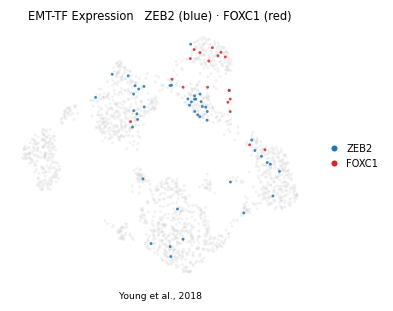

In [5]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g],2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))
colors = {sel[0]: 'tab:blue', sel[1]: 'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=5,label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.06, 'Young et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()
for g in sel:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (top decile)')
print('saved expression.pdf')